Original Dataset:
  StudentID  StudyHours  Attendance  PrevMarks  Marks Branch Result
0     S1000        5.08       82.32      65.44  82.46    ISE   Pass
1     S1001        6.16       68.27      82.55  79.14    CSD   Pass
2     S1002        5.42       98.16      67.71  76.89    CSE   Pass
3     S1003        2.93       79.50      68.25  62.16    ISE   Fail
4     S1004        8.01       93.33      60.55  86.49    ISE   Pass

Missing Values:
StudyHours    0
Attendance    0
PrevMarks     0
Marks         9
dtype: int64

Missing Values After Cleaning:
StudyHours    0
Attendance    0
PrevMarks     0
Marks         0
dtype: int64

Normalized Data:
[[0.3494152  0.69015072 0.50881182 0.67288325]
 [0.42836257 0.44391868 0.75198977 0.61096606]
 [0.37426901 0.96775324 0.54107447 0.5690041 ]
 ...
 [0.1995614  0.59235892 0.55884025 0.41197314]
 [0.13304094 0.49036102 0.95920978 0.47929877]
 [0.58552632 0.70539783 0.36981239 0.78049235]]

Standardized Data:
[[-2.59070019e-01  4.00760512e-01 -1.61220693

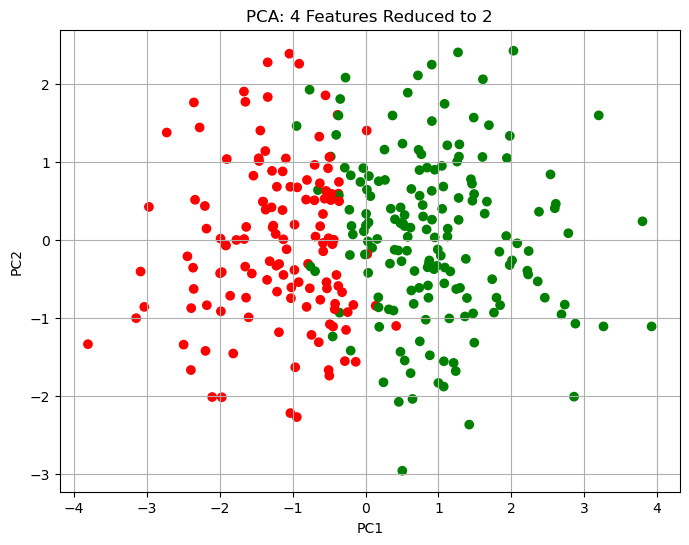


Lab completed successfully!


In [30]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# 1. Load dataset
df = pd.read_csv('students.csv')

print("Original Dataset:")
print(df.head())

# 2. Select numerical features
features = df[['StudyHours', 'Attendance', 'PrevMarks', 'Marks']].copy()

# 3. Convert into numeric values
features = features.apply(pd.to_numeric, errors='coerce')

# 4. Check missing values
print("\nMissing Values:")
print(features.isnull().sum())

# 5. Handle missing values
features = features.fillna(features.mean())

print("\nMissing Values After Cleaning:")
print(features.isnull().sum())

# 6. Min-Max Normalization
minmax = MinMaxScaler()
normalized = minmax.fit_transform(features)

print("\nNormalized Data:")
print(normalized)

# 7. Standardization
scaler = StandardScaler()
standardized = scaler.fit_transform(features)

print("\nStandardized Data:")
print(standardized)

print("\nMean:", standardized.mean().round(4))
print("Standard Deviation:", standardized.std().round(4))

# 8. PCA
pca = PCA(n_components=2)
principal_components = pca.fit_transform(standardized)

print("\nPCA Reduced Data:")
print(principal_components)

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("Total Variance Captured:",
      pca.explained_variance_ratio_.sum() * 100, "%")

# 9. PCA Visualization
colors = df['Result'].map({
    'Pass': 'green',
    'Fail': 'red'
})

plt.figure(figsize=(8, 6))

plt.scatter(
    principal_components[:, 0],
    principal_components[:, 1],
    c=colors
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA: 4 Features Reduced to 2')

plt.grid(True)
plt.show()

print("\nLab completed successfully!")